# 01 — Análise exploratória do tabuleiro

Este notebook explora a configuração selecionada do jogo. As métricas são descritivas: aluguel/preço não é retorno esperado, porque ainda não considera probabilidade de visita, propriedade dos terrenos, construção ou decisões dos jogadores.

**Execute a partir da raiz do repositório** para que os imports `app.*` sejam resolvidos.

## 1. Imports e carregamento da configuração

In [20]:

from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

# Garante que a raiz do projeto esteja disponível para os imports.
PROJECT_ROOT = Path("/media/marth/Dados/Arquivos/Monopoly-AI").resolve()

if not (PROJECT_ROOT / "app" / "main.py").is_file():
    raise FileNotFoundError(
        f"Raiz do projeto inválida: {PROJECT_ROOT}"
    )

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

# Imports do projeto.
from app.application.game_setup import load_selected_game
from app.domain.analytics.board import (
    analyze_board,
    build_space_table,
    build_property_table,
    summarize_property_groups,
)

# Carrega a configuração e prepara as tabelas.
game_config = load_selected_game()

spaces_df = pd.DataFrame(build_space_table(game_config))
properties_df = pd.DataFrame(build_property_table(game_config))

groups_df = pd.DataFrame(
    summarize_property_groups(properties_df.to_dict("records"))
)

# Resumo inicial.
print(f"Tabuleiro: {game_config.variant}")
print(f"Casas: {len(spaces_df)}")
print(f"Propriedades: {len(properties_df)}")
print(f"Grupos de cor: {len(groups_df)}")


Tabuleiro: classic_us
Casas: 40
Propriedades: 22
Grupos de cor: 8


## 2. Visão estrutural

In [21]:
summary = analyze_board(game_config)
summary_df = pd.DataFrame([
    {'metric': key, 'value': value}
    for key, value in summary.items()
    if key not in {'space_type_counts', 'property_groups'}
])
display(summary_df)
display(pd.DataFrame([
    {'space_type': space_type, 'count': count}
    for space_type, count in summary['space_type_counts'].items()
]).sort_values('count', ascending=False))

,metric,value
0,board_size,40.000000
1,property_count,22.000000
2,property_price_total,4590.000000
3,property_price_mean,208.636364
4,base_rent_mean,17.772727


,space_type,count
1,property,22
4,railroad,4
5,chance,3
2,community_chest,3
7,utility,2
3,tax,2
0,go,1
6,jail,1
8,free_parking,1
9,go_to_jail,1


## 3. Distribuição dos tipos de casa

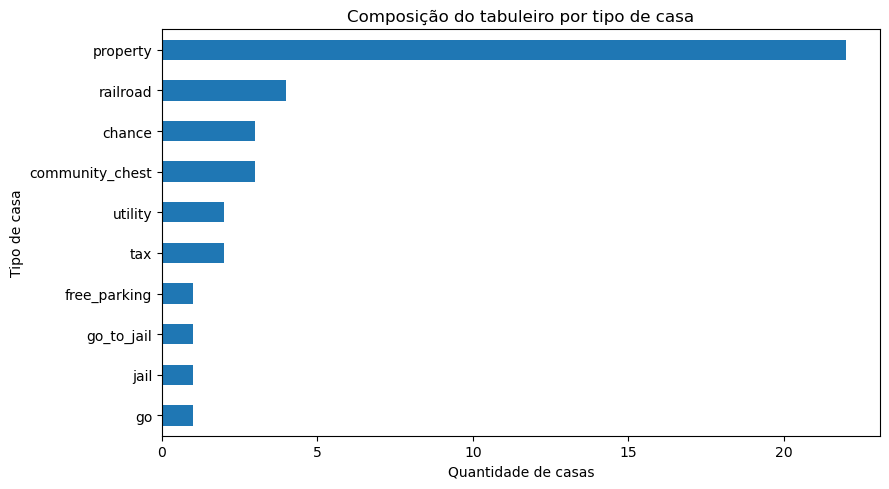

In [22]:
type_counts = spaces_df['type'].value_counts().sort_values()
ax = type_counts.plot(kind='barh', figsize=(9, 5))
ax.set_title('Composição do tabuleiro por tipo de casa')
ax.set_xlabel('Quantidade de casas')
ax.set_ylabel('Tipo de casa')
plt.tight_layout()
plt.show()

## 4. Preço de compra por propriedade

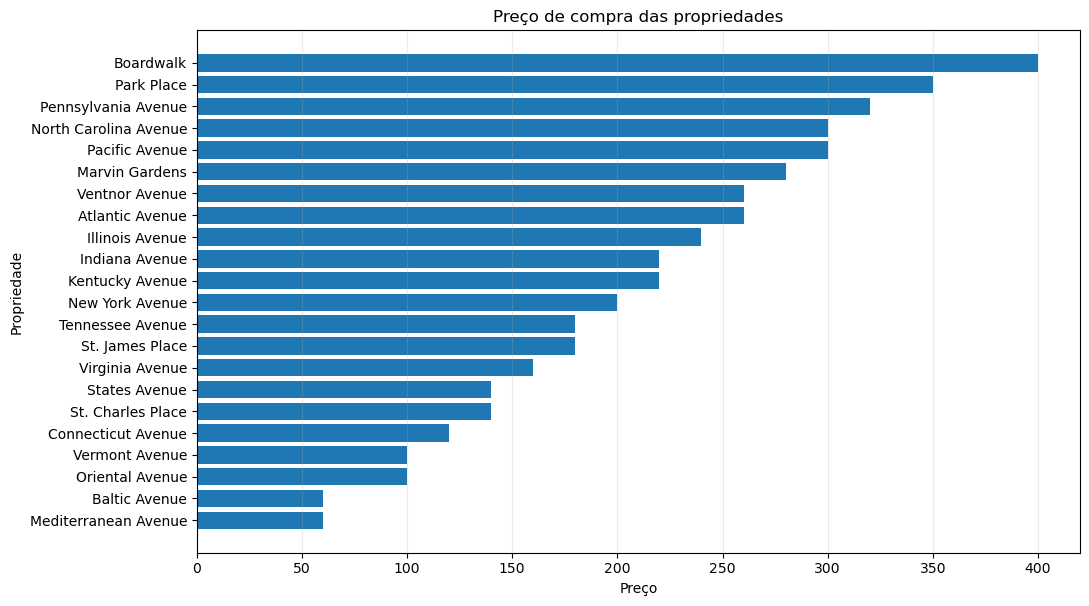

In [23]:
plot_df = properties_df.sort_values('price', ascending=True)
fig, ax = plt.subplots(figsize=(11, max(6, len(plot_df) * 0.28)))
ax.barh(plot_df['name'], plot_df['price'])
ax.set_title('Preço de compra das propriedades')
ax.set_xlabel('Preço')
ax.set_ylabel('Propriedade')
ax.grid(axis='x', alpha=0.25)
plt.tight_layout()
plt.show()

## 5. Aluguel-base e aluguel/preço

A razão aluguel-base/preço é apenas uma comparação estática. Não representa rentabilidade anual nem retorno esperado por turno.

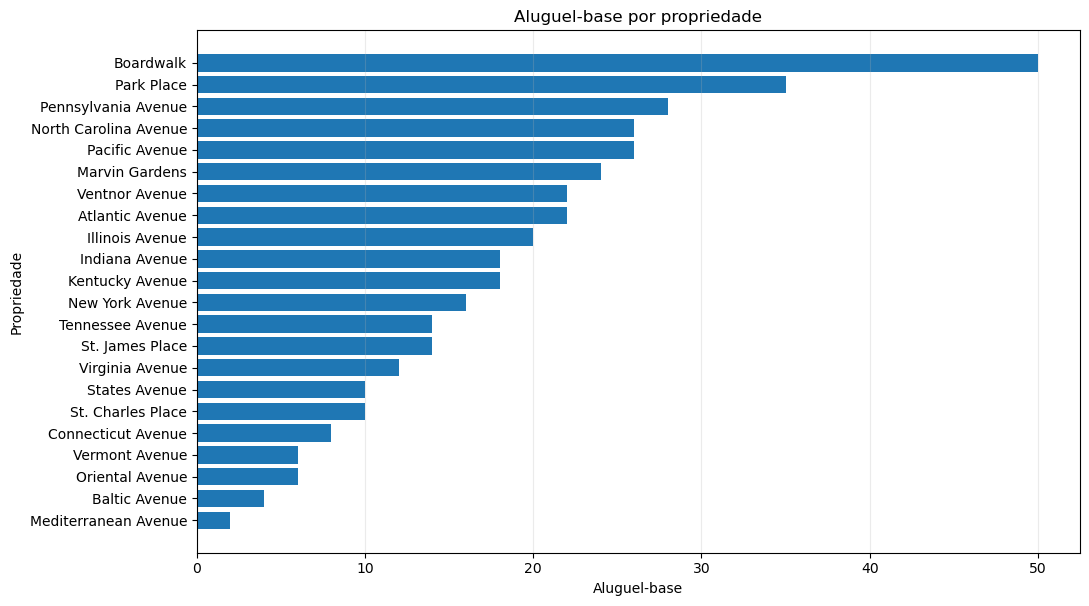

,name,color_group,price,rent_base,base_rent_to_price
21,Boardwalk,darkblue,400,50,12.50%
20,Park Place,darkblue,350,35,10.00%
19,Pennsylvania Avenue,green,320,28,8.75%
17,Pacific Avenue,green,300,26,8.67%
18,North Carolina Avenue,green,300,26,8.67%
16,Marvin Gardens,yellow,280,24,8.57%
15,Ventnor Avenue,yellow,260,22,8.46%
14,Atlantic Avenue,yellow,260,22,8.46%
13,Illinois Avenue,red,240,20,8.33%
11,Kentucky Avenue,red,220,18,8.18%


In [24]:
plot_df = properties_df.sort_values('rent_base', ascending=True)
fig, ax = plt.subplots(figsize=(11, max(6, len(plot_df) * 0.28)))
ax.barh(plot_df['name'], plot_df['rent_base'])
ax.set_title('Aluguel-base por propriedade')
ax.set_xlabel('Aluguel-base')
ax.set_ylabel('Propriedade')
ax.grid(axis='x', alpha=0.25)
plt.tight_layout()
plt.show()

display(properties_df[['name', 'color_group', 'price', 'rent_base', 'base_rent_to_price']]
        .sort_values('base_rent_to_price', ascending=False)
        .style.format({'price': '{:,.0f}', 'rent_base': '{:,.0f}', 'base_rent_to_price': '{:.2%}'}))

## 6. Comparação entre grupos de cor

,color_group,property_count,total_purchase_cost,mean_purchase_price,mean_base_rent,mean_base_rent_to_price,house_cost,hotel_cost
0,brown,2,120,60.000000,3.000000,0.050000,50,50
1,darkblue,2,750,375.000000,42.500000,0.112500,200,200
2,green,3,920,306.666667,26.666667,0.086944,200,200
3,lightblue,3,320,106.666667,6.666667,0.062222,50,50
4,orange,3,560,186.666667,14.666667,0.078519,100,100
5,pink,3,440,146.666667,10.666667,0.072619,100,100
6,red,3,680,226.666667,18.666667,0.082323,150,150
7,yellow,3,800,266.666667,22.666667,0.084982,150,150


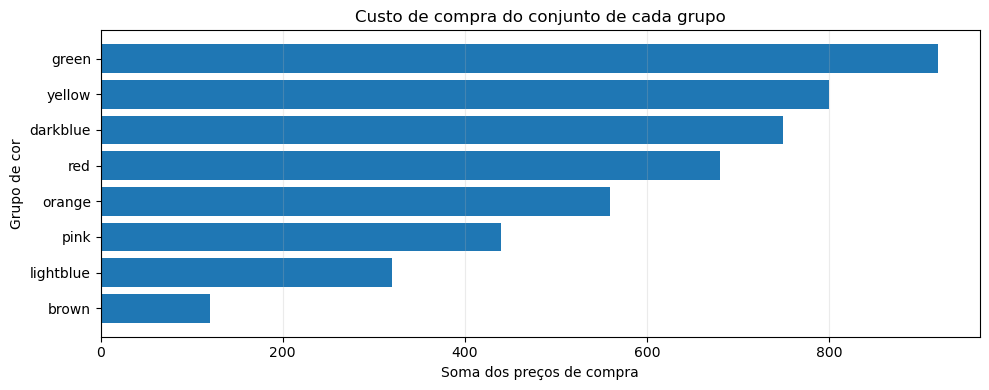

In [25]:
display(groups_df)

plot_groups = groups_df.sort_values('total_purchase_cost')
fig, ax = plt.subplots(figsize=(10, max(4, len(plot_groups) * 0.4)))
ax.barh(plot_groups['color_group'], plot_groups['total_purchase_cost'])
ax.set_title('Custo de compra do conjunto de cada grupo')
ax.set_xlabel('Soma dos preços de compra')
ax.set_ylabel('Grupo de cor')
ax.grid(axis='x', alpha=0.25)
plt.tight_layout()
plt.show()

## 7. Relação entre preço e aluguel-base

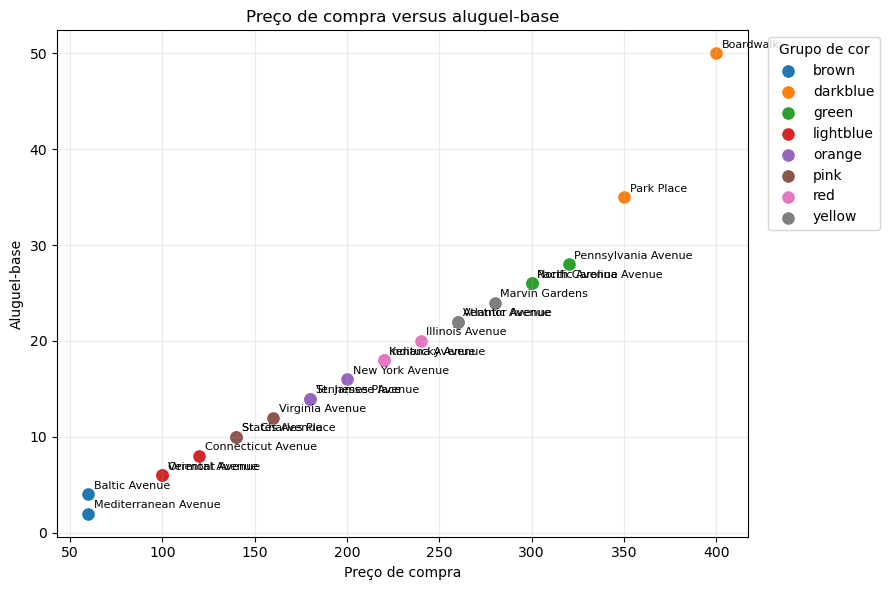

In [26]:
fig, ax = plt.subplots(figsize=(9, 6))
for group, subset in properties_df.groupby('color_group', dropna=False):
    ax.scatter(subset['price'], subset['rent_base'], label=str(group), s=65)
    for _, row in subset.iterrows():
        ax.annotate(row['name'], (row['price'], row['rent_base']), xytext=(4, 4),
                    textcoords='offset points', fontsize=8)
ax.set_title('Preço de compra versus aluguel-base')
ax.set_xlabel('Preço de compra')
ax.set_ylabel('Aluguel-base')
ax.grid(alpha=0.25)
ax.legend(title='Grupo de cor', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

## 8. Inspeção dos dados e limitações

A tabela abaixo ajuda a conferir se a configuração carregada contém os campos esperados. Antes de interpretar resultados, verifique se os nomes e valores correspondem à variante escolhida.

Próxima etapa: integrar as probabilidades de visita do módulo de Markov. Só depois disso poderemos construir estimativas de receita de aluguel sob hipóteses explícitas.

In [27]:
display(spaces_df.head(12))
display(properties_df)

,position,name,type,description,color_group,price,house_cost,hotel_cost,mortgage,unmortgage_cost,...,rent_hotel,tax_amount,tax_type,percent_option,rent_owned1,rent_owned2,rent_owned3,rent_owned4,rent_multiplier1,rent_multiplier2
0,0,Go,go,Collect $200 salary as you pass Go,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1,Mediterranean Avenue,property,NaN,brown,60.0,50.0,50.0,30.0,33.0,...,250.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2,Community Chest,community_chest,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,3,Baltic Avenue,property,NaN,brown,60.0,50.0,50.0,30.0,33.0,...,450.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,4,Income Tax,tax,"Pay $200 or 10% of your total worth, whichever...",NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,200.0,income,10.0,NaN,NaN,NaN,NaN,NaN,NaN
5,5,Reading Railroad,railroad,NaN,NaN,200.0,NaN,NaN,100.0,110.0,...,NaN,NaN,NaN,NaN,25.0,50.0,100.0,200.0,NaN,NaN
6,6,Oriental Avenue,property,NaN,lightblue,100.0,50.0,50.0,50.0,55.0,...,550.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,7,Chance,chance,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,8,Vermont Avenue,property,NaN,lightblue,100.0,50.0,50.0,50.0,55.0,...,550.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,9,Connecticut Avenue,property,NaN,lightblue,120.0,50.0,50.0,60.0,66.0,...,600.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,position,name,color_group,price,house_cost,hotel_cost,mortgage,unmortgage_cost,rent_base,rent_monopoly,rent_one_house,rent_two_houses,rent_three_houses,rent_four_houses,rent_hotel,base_rent_to_price,monopoly_rent_to_price
0,1,Mediterranean Avenue,brown,60,50,50,30,33,2,4,10,30,90,160,250,0.033333,0.066667
1,3,Baltic Avenue,brown,60,50,50,30,33,4,8,20,60,180,320,450,0.066667,0.133333
2,6,Oriental Avenue,lightblue,100,50,50,50,55,6,12,30,90,270,400,550,0.060000,0.120000
3,8,Vermont Avenue,lightblue,100,50,50,50,55,6,12,30,90,270,400,550,0.060000,0.120000
4,9,Connecticut Avenue,lightblue,120,50,50,60,66,8,16,40,100,300,450,600,0.066667,0.133333
5,11,St. Charles Place,pink,140,100,100,70,77,10,20,50,150,450,625,750,0.071429,0.142857
6,13,States Avenue,pink,140,100,100,70,77,10,20,50,150,450,625,750,0.071429,0.142857
7,14,Virginia Avenue,pink,160,100,100,80,88,12,24,60,180,500,700,900,0.075000,0.150000
8,16,St. James Place,orange,180,100,100,90,99,14,28,70,200,550,750,950,0.077778,0.155556
9,18,Tennessee Avenue,orange,180,100,100,90,99,14,28,70,200,550,750,950,0.077778,0.155556


In [48]:

from dataclasses import dataclass
from collections import defaultdict

from app.domain.analytics.markov.state_space import StateSpace
from app.domain.analytics.markov.transition_model import TransitionModel
from app.domain.analytics.markov.transition_matrix import TransitionMatrix
from app.domain.analytics.markov.stationary import (
    calculate_stationary_distribution,
)


@dataclass(frozen=True, slots=True)
class MonopolyState:
    position: int
    in_jail: bool = False
    jail_attempts: int = 0
    doubles_streak: int = 0


class MonopolyBoardModel(TransitionModel):
    """
    Modelo de Markov simplificado para a posição de um jogador.

    A transição ocorre a cada rolagem de dados.
    Os efeitos das cartas são aproximados por uma probabilidade fixa
    de ir para a prisão nas casas de cartas.
    """

    BOARD_SIZE = 40
    JAIL_POSITION = 10
    GO_TO_JAIL_POSITION = 30

    CHANCE_POSITIONS = {7, 22, 36}
    COMMUNITY_CHEST_POSITIONS = {2, 17, 33}
    CARD_JAIL_PROBABILITY = 1 / 16

    MAX_DOUBLES = 3
    MAX_JAIL_ATTEMPTS = 3

    def __init__(self):
        states = []

        # Estados fora da prisão.
        for position in range(self.BOARD_SIZE):
            for doubles_streak in range(self.MAX_DOUBLES):
                states.append(
                    MonopolyState(
                        position=position,
                        in_jail=False,
                        jail_attempts=0,
                        doubles_streak=doubles_streak,
                    )
                )

        # Estados na prisão.
        for attempts in range(self.MAX_JAIL_ATTEMPTS):
            states.append(
                MonopolyState(
                    position=self.JAIL_POSITION,
                    in_jail=True,
                    jail_attempts=attempts,
                    doubles_streak=0,
                )
            )

        super().__init__(StateSpace(states))
        self._transition_cache = {}


    def transitions_from(self, source):
        if source not in self._transition_cache:
            self._transition_cache[source] = self._calculate_transitions(
                source
            )

        # TransitionMatrix espera pares (estado_destino, probabilidade).
        return tuple(self._transition_cache[source].items())

    def probability(self, source, target):
        # Garante que as transições estejam calculadas.
        self.transitions_from(source)
        return self._transition_cache[source].get(target, 0.0)


    def _calculate_transitions(self, source):
        probabilities = defaultdict(float)

        # Enumera os 36 resultados ordenados dos dois dados.
        for die1 in range(1, 7):
            for die2 in range(1, 7):
                total = die1 + die2
                is_double = die1 == die2

                if source.in_jail:
                    self._jail_transition(
                        source, total, is_double, probabilities
                    )
                else:
                    self._normal_transition(
                        source, total, is_double, probabilities
                    )

        # Cada resultado ordenado tem probabilidade 1/36.
        return dict(probabilities)

    def _normal_transition(
        self, source, total, is_double, probabilities
    ):
        streak = source.doubles_streak + 1 if is_double else 0

        # Terceira dupla consecutiva: vai para a prisão sem andar.
        if is_double and streak >= self.MAX_DOUBLES:
            target = MonopolyState(
                position=self.JAIL_POSITION,
                in_jail=True,
                jail_attempts=0,
                doubles_streak=0,
            )
            probabilities[target] += 1 / 36
            return

        position = (source.position + total) % self.BOARD_SIZE

        self._resolve_landing(
            position=position,
            doubles_streak=streak,
            probabilities=probabilities,
        )

    def _jail_transition(
        self, source, total, is_double, probabilities
    ):
        next_attempt = source.jail_attempts + 1

        # Uma dupla libera o jogador e movimenta a peça,
        # sem conceder rolagem extra neste turno.
        # Na terceira tentativa sem dupla, paga a multa e se move.
        released = is_double or (
            next_attempt >= self.MAX_JAIL_ATTEMPTS
        )

        if released:
            position = (self.JAIL_POSITION + total) % self.BOARD_SIZE
            self._resolve_landing(
                position=position,
                doubles_streak=0,
                probabilities=probabilities,
            )
        else:
            target = MonopolyState(
                position=self.JAIL_POSITION,
                in_jail=True,
                jail_attempts=next_attempt,
                doubles_streak=0,
            )
            probabilities[target] += 1 / 36

    def _resolve_landing(
        self, position, doubles_streak, probabilities
    ):
        # Casa "Vá para a prisão".
        if position == self.GO_TO_JAIL_POSITION:
            target = MonopolyState(
                position=self.JAIL_POSITION,
                in_jail=True,
                jail_attempts=0,
                doubles_streak=0,
            )
            probabilities[target] += 1 / 36
            return

        # Aproximação: cada casa de cartas tem probabilidade 1/16
        # de enviar o jogador à prisão. Demais efeitos são ignorados.
        card_position = (
            position in self.CHANCE_POSITIONS
            or position in self.COMMUNITY_CHEST_POSITIONS
        )

        if card_position:
            jail_probability = self.CARD_JAIL_PROBABILITY

            jail_state = MonopolyState(
                position=self.JAIL_POSITION,
                in_jail=True,
                jail_attempts=0,
                doubles_streak=0,
            )
            normal_state = MonopolyState(
                position=position,
                in_jail=False,
                jail_attempts=0,
                doubles_streak=doubles_streak,
            )

            probabilities[jail_state] += jail_probability / 36
            probabilities[normal_state] += (
                1 - jail_probability
            ) / 36
        else:
            target = MonopolyState(
                position=position,
                in_jail=False,
                jail_attempts=0,
                doubles_streak=doubles_streak,
            )
            probabilities[target] += 1 / 36


In [49]:

model = MonopolyBoardModel()
matrix = TransitionMatrix(model)

print("Quantidade de estados:", model.state_space.size)
print("Dimensão da matriz:", matrix.matrix.shape)

row_sums = matrix.matrix.sum(axis=1)

print("Menor soma de linha:", row_sums.min())
print("Maior soma de linha:", row_sums.max())
print("Todas as linhas somam 1:", abs(row_sums - 1).max() < 1e-9)


Quantidade de estados: 123
Dimensão da matriz: (123, 123)
Menor soma de linha: 0.9999999999999999
Maior soma de linha: 1.0000000000000002
Todas as linhas somam 1: True


In [50]:

import numpy as np

distribuicao = calculate_stationary_distribution(matrix)

print("Soma das probabilidades:", distribuicao.sum())
print("Menor probabilidade:", distribuicao.min())
print("Maior probabilidade:", distribuicao.max())
print("Quantidade de estados:", len(distribuicao))


Soma das probabilidades: 0.9999999999999999
Menor probabilidade: 0.0
Maior probabilidade: 0.037473062578690014
Quantidade de estados: 123


In [51]:

import pandas as pd

probabilidade_por_casa = np.zeros(model.BOARD_SIZE)

for estado, probabilidade in zip(
    model.state_space.states,
    distribuicao
):
    probabilidade_por_casa[estado.position] += probabilidade

resultado = pd.DataFrame({
    "posição": range(model.BOARD_SIZE),
    "probabilidade": probabilidade_por_casa,
    "porcentagem": probabilidade_por_casa * 100
})

resultado["porcentagem"] = resultado["porcentagem"].round(3)

resultado.sort_values(
    "probabilidade", ascending=False
).head(10)


,posição,probabilidade,porcentagem
10,10,0.115653,11.565
18,18,0.027424,2.742
20,20,0.027175,2.717
16,16,0.026629,2.663
27,27,0.025659,2.566
26,26,0.025627,2.563
28,28,0.025576,2.558
25,25,0.025516,2.552
29,29,0.025476,2.548
19,19,0.025368,2.537


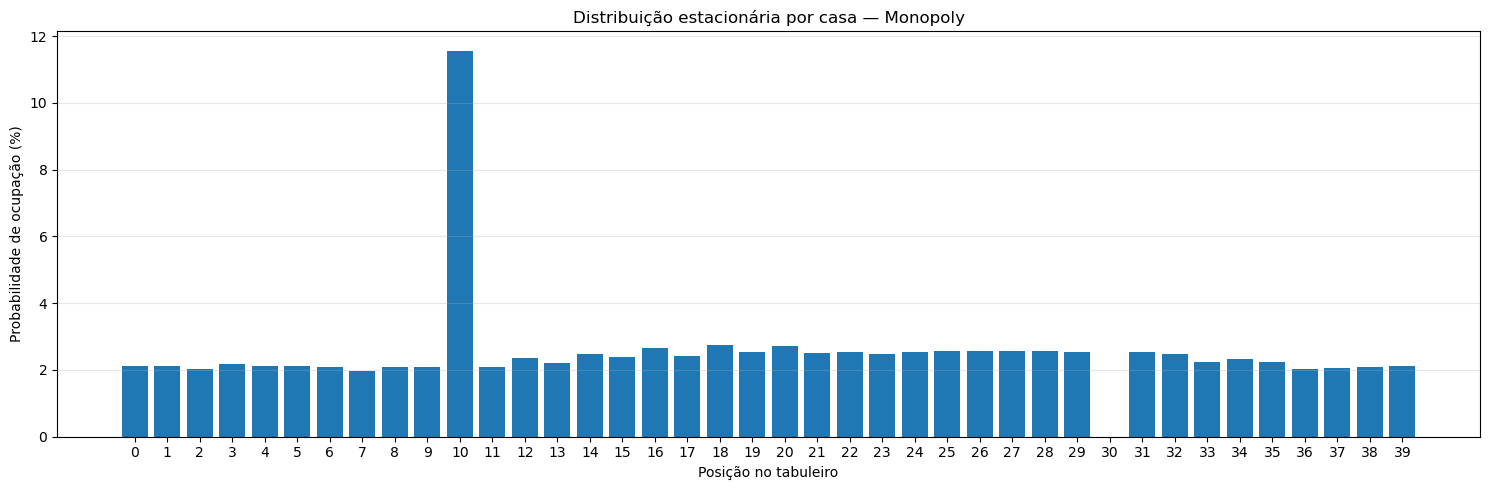

In [52]:

import matplotlib.pyplot as plt

plt.figure(figsize=(15, 5))
plt.bar(
    resultado["posição"],
    resultado["porcentagem"]
)
plt.xlabel("Posição no tabuleiro")
plt.ylabel("Probabilidade de ocupação (%)")
plt.title("Distribuição estacionária por casa — Monopoly")
plt.xticks(range(0, 40))
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


/tmp/ipykernel_25425/1690225983.py:375: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0.02, 0.10, 0.87, 0.94])


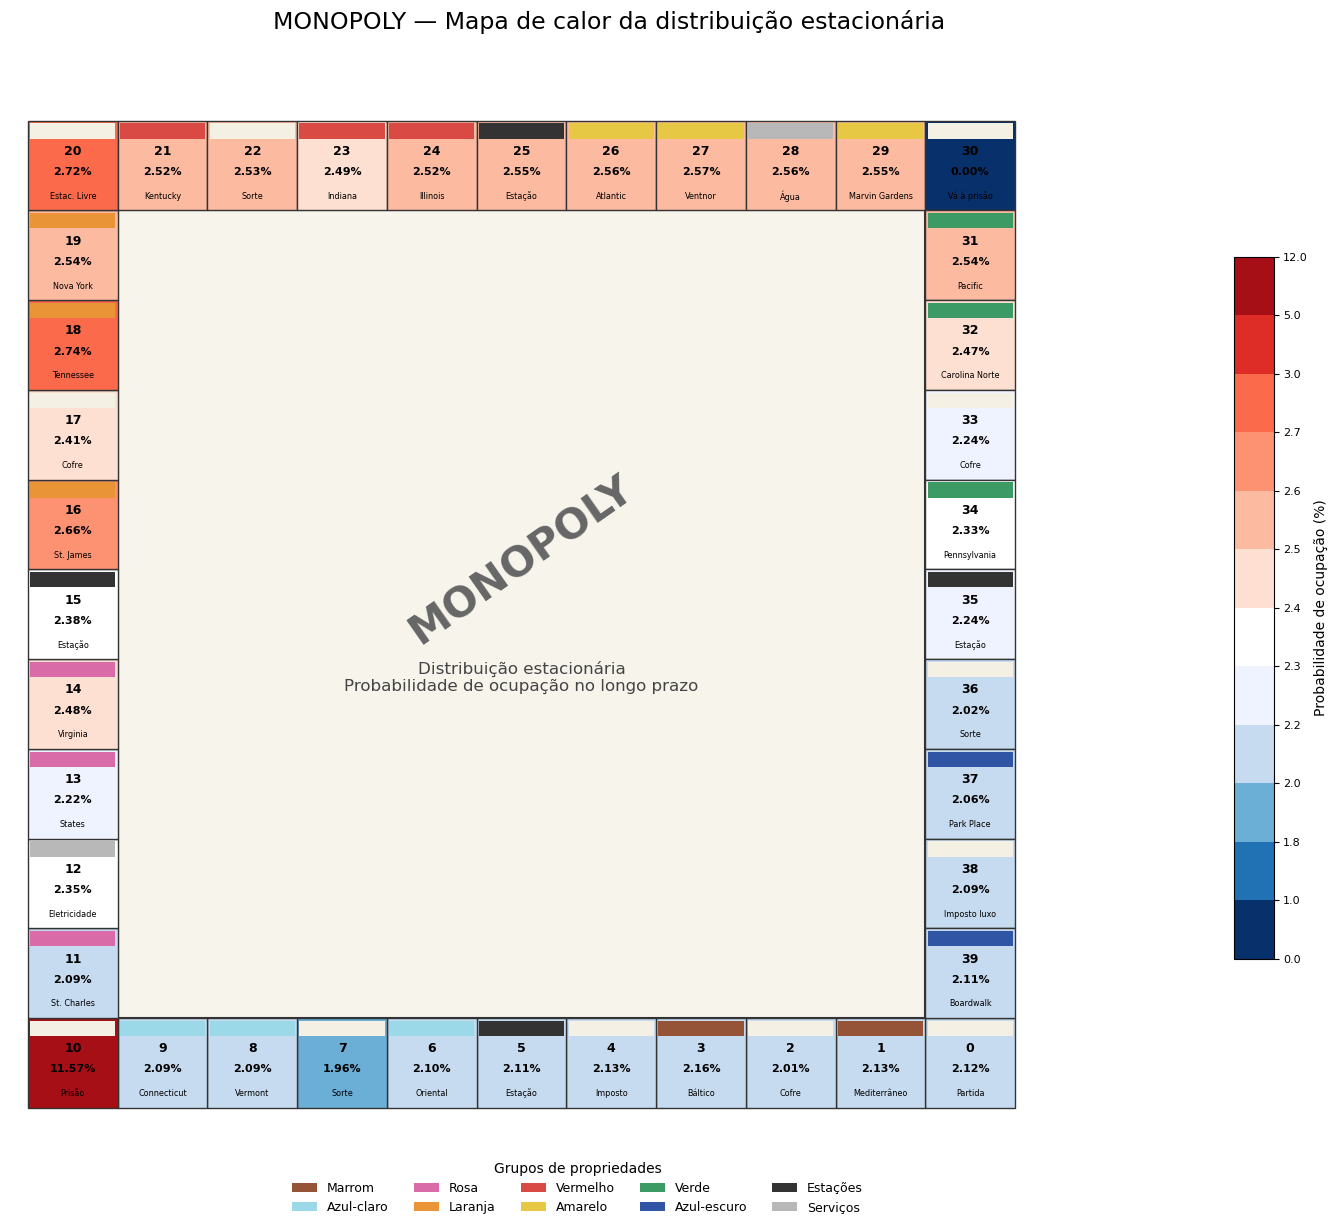

In [55]:

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.colorbar import ColorbarBase

# ============================================================
# 1. PROBABILIDADES
# ============================================================

valores = np.asarray(probabilidade_por_casa, dtype=float) * 100

if len(valores) != 40:
    raise ValueError("Esperávamos 40 probabilidades, uma para cada casa.")

# ============================================================
# 2. POSIÇÕES DAS CASAS NO TABULEIRO
# ============================================================

coordenadas = {}

# Parte inferior: 0 a 10, da direita para a esquerda
for pos in range(11):
    coordenadas[pos] = (10 - pos, 0)

# Lateral esquerda: 11 a 20, de baixo para cima
for pos in range(11, 21):
    coordenadas[pos] = (0, pos - 10)

# Parte superior: 21 a 30, da esquerda para a direita
for pos in range(21, 31):
    coordenadas[pos] = (pos - 20, 10)

# Lateral direita: 31 a 39, de cima para baixo
for pos in range(31, 40):
    coordenadas[pos] = (10, 40 - pos)

# ============================================================
# 3. NOMES DAS CASAS
# ============================================================

nomes = [
    "Partida",
    "Mediterrâneo",
    "Cofre",
    "Báltico",
    "Imposto",
    "Estação",
    "Oriental",
    "Sorte",
    "Vermont",
    "Connecticut",
    "Prisão",
    "St. Charles",
    "Eletricidade",
    "States",
    "Virginia",
    "Estação",
    "St. James",
    "Cofre",
    "Tennessee",
    "Nova York",
    "Estac. Livre",
    "Kentucky",
    "Sorte",
    "Indiana",
    "Illinois",
    "Estação",
    "Atlantic",
    "Ventnor",
    "Água",
    "Marvin Gardens",
    "Vá à prisão",
    "Pacific",
    "Carolina Norte",
    "Cofre",
    "Pennsylvania",
    "Estação",
    "Sorte",
    "Park Place",
    "Imposto luxo",
    "Boardwalk"
]

# ============================================================
# 4. CORES DOS GRUPOS IMOBILIÁRIOS
# ============================================================

cores_grupo = {
    "Marrom": "#955438",
    "Azul-claro": "#9BD8E8",
    "Rosa": "#D96CA8",
    "Laranja": "#E99436",
    "Vermelho": "#D84A43",
    "Amarelo": "#E7C844",
    "Verde": "#3C9B65",
    "Azul-escuro": "#3155A5",
    "Estações": "#333333",
    "Serviços": "#B8B8B8",
    "Especial": "#F5F0E4"
}

grupo_por_posicao = {
    # Marrom
    1: "Marrom",
    3: "Marrom",

    # Azul-claro
    6: "Azul-claro",
    8: "Azul-claro",
    9: "Azul-claro",

    # Rosa
    11: "Rosa",
    13: "Rosa",
    14: "Rosa",

    # Laranja
    16: "Laranja",
    18: "Laranja",
    19: "Laranja",

    # Vermelho
    21: "Vermelho",
    23: "Vermelho",
    24: "Vermelho",

    # Amarelo
    26: "Amarelo",
    27: "Amarelo",
    29: "Amarelo",

    # Verde
    31: "Verde",
    32: "Verde",
    34: "Verde",

    # Azul-escuro
    37: "Azul-escuro",
    39: "Azul-escuro",

    # Estações
    5: "Estações",
    15: "Estações",
    25: "Estações",
    35: "Estações",

    # Serviços
    12: "Serviços",
    28: "Serviços"
}

# ============================================================
# 5. MAPA DE CALOR AZUL–BRANCO–VERMELHO
# ============================================================

# Cada intervalo recebe uma cor distinta.
# Os limites foram escolhidos para destacar diferenças
# entre as casas mais próximas de 2% a 3%.

limites = [
    0.0,
    1.0,
    1.8,
    2.0,
    2.2,
    2.3,
    2.4,
    2.5,
    2.6,
    2.7,
    3.0,
    5.0,
    12.0
]

cores_calor = [
    "#08306B",  # Muito frio: abaixo de 1%
    "#2171B5",  # Azul forte
    "#6BAED6",  # Azul médio
    "#C6DBEF",  # Azul-claro
    "#EFF3FF",  # Azul muito suave
    "#FFFFFF",  # Próximo do neutro
    "#FEE0D2",  # Rosa muito suave
    "#FCBBA1",  # Rosa suave
    "#FC9272",  # Vermelho-claro
    "#FB6A4A",  # Vermelho
    "#DE2D26",  # Vermelho forte
    "#A50F15"   # Muito quente
]

mapa_calor = ListedColormap(cores_calor)

normalizar = BoundaryNorm(
    limites,
    ncolors=mapa_calor.N,
    clip=True
)

# ============================================================
# 6. DESENHO DO TABULEIRO
# ============================================================

fig, ax = plt.subplots(figsize=(16, 13))

ax.set_xlim(-0.2, 11.2)
ax.set_ylim(-0.2, 11.2)
ax.set_aspect("equal")
ax.axis("off")

fig.suptitle(
    "MONOPOLY — Mapa de calor da distribuição estacionária",
    fontsize=17,
    y=0.97
)

# Centro do tabuleiro
ax.add_patch(
    Rectangle(
        (1, 1),
        9,
        9,
        facecolor="#F7F4EC",
        edgecolor="#333333",
        linewidth=1.5
    )
)

ax.text(
    5.5,
    6.1,
    "MONOPOLY",
    ha="center",
    va="center",
    fontsize=30,
    weight="bold",
    rotation=35,
    color="#666666"
)

ax.text(
    5.5,
    4.8,
    "Distribuição estacionária\nProbabilidade de ocupação no longo prazo",
    ha="center",
    va="center",
    fontsize=12,
    color="#444444"
)

# Desenhar cada casa
for pos, (x, y) in coordenadas.items():

    prob = valores[pos]
    cor_calor = mapa_calor(normalizar(prob))

    # Fundo conforme frequência de ocupação
    ax.add_patch(
        Rectangle(
            (x, y),
            1,
            1,
            facecolor=cor_calor,
            edgecolor="#333333",
            linewidth=1.0
        )
    )

    # Faixa superior conforme grupo imobiliário
    grupo = grupo_por_posicao.get(pos, "Especial")

    ax.add_patch(
        Rectangle(
            (x + 0.025, y + 0.80),
            0.95,
            0.17,
            facecolor=cores_grupo[grupo],
            edgecolor="none"
        )
    )

    # Número da casa
    ax.text(
        x + 0.5,
        y + 0.66,
        str(pos),
        ha="center",
        va="center",
        fontsize=9,
        weight="bold"
    )

    # Probabilidade
    ax.text(
        x + 0.5,
        y + 0.43,
        f"{prob:.2f}%",
        ha="center",
        va="center",
        fontsize=8,
        weight="bold"
    )

    # Nome
    ax.text(
        x + 0.5,
        y + 0.16,
        nomes[pos],
        ha="center",
        va="center",
        fontsize=5.8
    )

# ============================================================
# 7. LEGENDA DISCRETA DO MAPA DE CALOR
# ============================================================

cax = fig.add_axes([0.89, 0.24, 0.025, 0.54])

barra = ColorbarBase(
    cax,
    cmap=mapa_calor,
    norm=normalizar,
    boundaries=limites,
    ticks=limites,
    spacing="uniform",
    orientation="vertical"
)

barra.set_label(
    "Probabilidade de ocupação (%)",
    fontsize=10
)

barra.ax.tick_params(labelsize=8)

# ============================================================
# 8. LEGENDA DOS GRUPOS
# ============================================================

ordem_grupos = [
    "Marrom",
    "Azul-claro",
    "Rosa",
    "Laranja",
    "Vermelho",
    "Amarelo",
    "Verde",
    "Azul-escuro",
    "Estações",
    "Serviços"
]

fig.legend(
    handles=[
        Rectangle(
            (0, 0),
            1,
            1,
            facecolor=cores_grupo[grupo],
            edgecolor="none",
            label=grupo
        )
        for grupo in ordem_grupos
    ],
    loc="lower center",
    bbox_to_anchor=(0.48, 0.035),
    ncol=5,
    frameon=False,
    fontsize=9,
    title="Grupos de propriedades",
    title_fontsize=10
)

plt.tight_layout(rect=[0.02, 0.10, 0.87, 0.94])
plt.show()
